In [1]:
# ============================================================
# Celda 1: Importación de librerías y configuración inicial
# ============================================================
# En esta celda se importan las librerías necesarias para la selección
# de características. Se utilizarán métodos estadísticos y modelos de
# Machine Learning para identificar las variables más relevantes.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, f1_score, classification_report

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

DATASET_PATH = "dataset-phishing-clean.csv"
TARGET_COL = "status"

COLOR_PRIMARIO = "#3A6EA5"
COLOR_SECUNDARIO = "#5DADE2"
COLOR_TERCIARIO = "#95A5A6"

# Número de características a visualizar/seleccionar
TOP_N = 25

sns.set_theme(style="whitegrid")

In [2]:
# ============================================================
# Celda 2: Carga del dataset limpio
# ============================================================
# En esta celda se carga el dataset previamente limpiado en el notebook 02.
# Este será el punto de partida para seleccionar las características
# más relevantes para el modelo.

df = pd.read_csv(DATASET_PATH)

print("Shape del dataset limpio:", df.shape)
display(df.head())

print("\nColumnas disponibles:")
print(df.columns.tolist())

Shape del dataset limpio: (11429, 83)


,url,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_eq,nb_underscore,nb_tilde,nb_percent,nb_slash,nb_star,nb_colon,nb_comma,nb_semicolumn,nb_dollar,nb_space,nb_www,nb_com,nb_dslash,http_in_path,https_token,ratio_digits_url,ratio_digits_host,punycode,port,tld_in_path,tld_in_subdomain,abnormal_subdomain,nb_subdomains,prefix_suffix,random_domain,shortening_service,path_extension,nb_redirection,nb_external_redirection,length_words_raw,char_repeat,shortest_words_raw,shortest_word_host,shortest_word_path,longest_words_raw,longest_word_host,longest_word_path,avg_words_raw,avg_word_host,avg_word_path,phish_hints,domain_in_brand,brand_in_subdomain,brand_in_path,suspecious_tld,statistical_report,nb_hyperlinks,ratio_intHyperlinks,ratio_extHyperlinks,nb_extCSS,ratio_extRedirection,ratio_extErrors,login_form,external_favicon,links_in_tags,ratio_intMedia,ratio_extMedia,iframe,popup_window,safe_anchor,onmouseover,right_clic,empty_title,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank,status
0,http://www.crestonwood.com/router.php,37,19,0,3,0,0,0,0,0,0,0,0,3,0,1,0,0,0,0,1,0,0,0,1,0.000000,0.0,0,0,0,0,0,3,0,0,0,0,0,0,4,4,3,3,3,11,11,6,5.750000,7.0,4.500000,0,0,0,0,0,0,17,0.529412,0.470588,0,0.875000,0.500000,0,0,80.000000,100.000000,0.000000,0,0,0.0,0,0,0,0,1,0,45,-1,0,1,1,4,0
1,http://shadetreetechnology.com/V4/validation/a...,77,23,1,1,0,0,0,0,0,0,0,0,5,0,1,0,0,0,0,0,0,0,0,1,0.220779,0.0,0,0,0,0,0,1,0,0,0,0,1,0,4,4,2,19,2,32,19,32,15.750000,19.0,14.666667,0,0,0,0,0,0,30,0.966667,0.033333,0,0.000000,0.000000,0,0,100.000000,80.000000,20.000000,0,0,100.0,0,0,0,1,0,0,77,5767,0,0,1,2,1
2,https://support-appleld.com.secureupdate.duila...,126,50,1,4,1,0,1,2,3,2,0,0,5,0,1,0,0,0,0,0,1,0,0,0,0.150794,0.0,0,0,0,1,0,3,1,0,0,0,1,0,12,2,2,3,2,17,13,17,8.250000,8.4,8.142857,0,0,0,0,0,0,4,1.000000,0.000000,0,0.000000,0.000000,0,0,100.000000,0.000000,0.000000,0,0,100.0,0,0,0,1,0,0,14,4004,5828815,0,1,0,1
3,http://rgipt.ac.in,18,11,0,2,0,0,0,0,0,0,0,0,2,0,1,0,0,0,0,0,0,0,0,1,0.000000,0.0,0,0,0,0,0,2,0,0,0,0,1,0,1,0,5,5,0,5,5,0,5.000000,5.0,0.000000,0,0,0,0,0,0,149,0.973154,0.026846,0,0.250000,0.250000,0,0,100.000000,96.428571,3.571429,0,0,62.5,0,0,0,1,0,0,62,-1,107721,0,0,3,0
4,http://www.iracing.com/tracks/gateway-motorspo...,55,15,0,2,2,0,0,0,0,0,0,0,5,0,1,0,0,0,0,1,0,0,0,1,0.000000,0.0,0,0,0,0,0,2,0,0,0,0,1,0,6,3,3,3,4,11,7,11,6.333333,5.0,7.000000,0,0,0,0,0,0,102,0.470588,0.529412,0,0.537037,0.018519,1,0,76.470588,0.000000,100.000000,0,0,0.0,0,0,0,0,1,0,224,8175,8725,0,0,6,0



Columnas disponibles:
['url', 'length_url', 'length_hostname', 'ip', 'nb_dots', 'nb_hyphens', 'nb_at', 'nb_qm', 'nb_and', 'nb_eq', 'nb_underscore', 'nb_tilde', 'nb_percent', 'nb_slash', 'nb_star', 'nb_colon', 'nb_comma', 'nb_semicolumn', 'nb_dollar', 'nb_space', 'nb_www', 'nb_com', 'nb_dslash', 'http_in_path', 'https_token', 'ratio_digits_url', 'ratio_digits_host', 'punycode', 'port', 'tld_in_path', 'tld_in_subdomain', 'abnormal_subdomain', 'nb_subdomains', 'prefix_suffix', 'random_domain', 'shortening_service', 'path_extension', 'nb_redirection', 'nb_external_redirection', 'length_words_raw', 'char_repeat', 'shortest_words_raw', 'shortest_word_host', 'shortest_word_path', 'longest_words_raw', 'longest_word_host', 'longest_word_path', 'avg_words_raw', 'avg_word_host', 'avg_word_path', 'phish_hints', 'domain_in_brand', 'brand_in_subdomain', 'brand_in_path', 'suspecious_tld', 'statistical_report', 'nb_hyperlinks', 'ratio_intHyperlinks', 'ratio_extHyperlinks', 'nb_extCSS', 'ratio_extRedi

In [3]:
# ============================================================
# Celda 3: Separación de variables predictoras y variable objetivo
# ============================================================
# En esta celda se separa el dataset en X e y.
# La columna URL se excluye porque no se usa directamente para entrenar,
# mientras que status corresponde a la variable objetivo.

cols_no_predictoras = ["url", TARGET_COL]

X = df.drop(columns=cols_no_predictoras, errors="ignore")
y = df[TARGET_COL]

print("Shape X:", X.shape)
print("Shape y:", y.shape)

print("\nDistribución de clases:")
display(y.value_counts())

Shape X: (11429, 81)
Shape y: (11429,)

Distribución de clases:


status
0    5715
1    5714
Name: count, dtype: int64

In [4]:
# ============================================================
# Celda 4: Validación de datos antes de seleccionar features
# ============================================================
# En esta celda se verifica que todas las variables predictoras sean numéricas
# y que no existan valores nulos o infinitos antes de aplicar métodos
# de selección de características.

for col in X.columns:
    X[col] = pd.to_numeric(X[col], errors="coerce")

X = X.replace([np.inf, -np.inf], np.nan)

for col in X.columns:
    if X[col].isnull().sum() > 0:
        X[col] = X[col].fillna(X[col].median())

print("Valores nulos en X:", X.isnull().sum().sum())
print("Valores infinitos en X:", np.isinf(X).sum().sum())

print("\nTipos de datos:")
display(X.dtypes.value_counts())

Valores nulos en X: 0
Valores infinitos en X: 0

Tipos de datos:


int64      68
float64    13
Name: count, dtype: int64

In [5]:
# ============================================================
# Celda 5: Eliminación de características no extraíbles en producción
# ============================================================
# En esta celda se eliminan variables que no pueden obtenerse de forma
# confiable al ingresar una URL nueva. Esto permite que la selección
# de características considere únicamente atributos utilizables
# en un sistema real de predicción.

FEATURES_NO_EXTRAIBLES = [
    "web_traffic",
    "page_rank"
]

features_a_eliminar = [
    col for col in FEATURES_NO_EXTRAIBLES
    if col in X.columns
]

print("Features no extraíbles eliminadas:")
print(features_a_eliminar)

X = X.drop(columns=features_a_eliminar, errors="ignore")

print("\nShape X después de eliminar features no extraíbles:", X.shape)

Features no extraíbles eliminadas:
['web_traffic', 'page_rank']

Shape X después de eliminar features no extraíbles: (11429, 79)


In [6]:
# ============================================================
# Celda 6: División train/test para selección de características
# ============================================================
# En esta celda se divide el dataset en entrenamiento y prueba.
# Esta división permite calcular importancias evitando evaluar sobre
# los mismos datos utilizados para entrenar los modelos.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (9143, 79)
X_test: (2286, 79)
y_train: (9143,)
y_test: (2286,)


,feature,rf_importance
78,google_index,0.197725
55,nb_hyperlinks,0.088053
19,nb_www,0.052957
76,domain_age,0.052582
57,ratio_extHyperlinks,0.037241
49,phish_hints,0.036258
56,ratio_intHyperlinks,0.032881
45,longest_word_path,0.032205
68,safe_anchor,0.029790
24,ratio_digits_url,0.029337


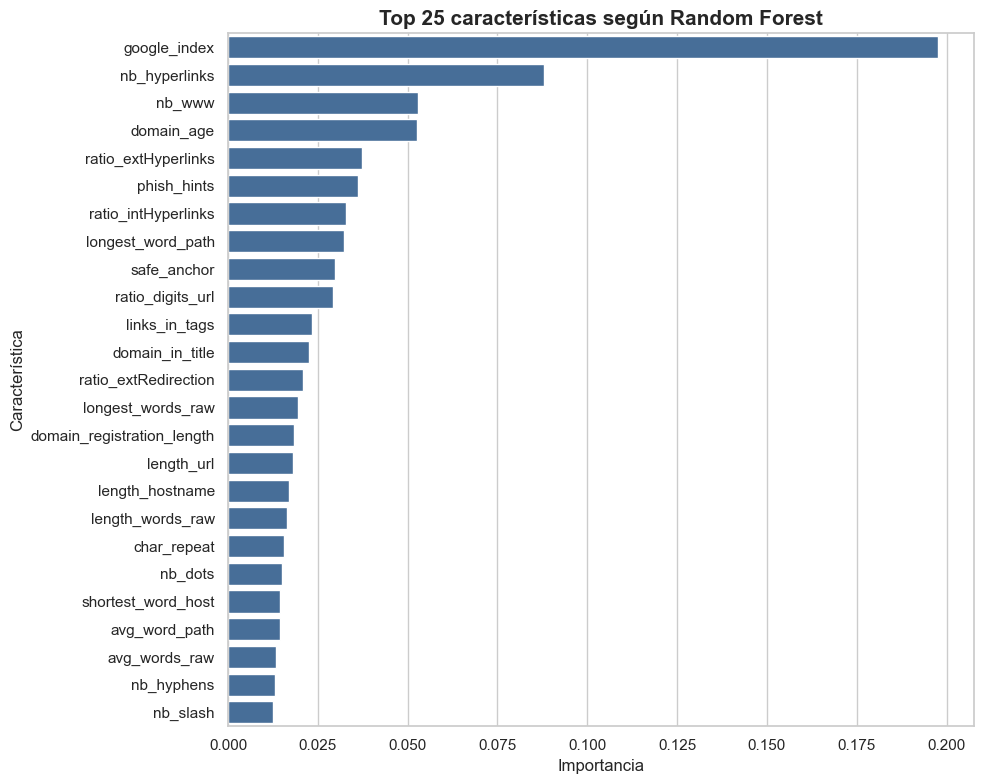

In [7]:
# ============================================================
# Celda 7: Importancia de características con Random Forest
# ============================================================
# En esta celda se entrena un modelo Random Forest para obtener
# una primera estimación de importancia de variables. Este método
# permite capturar relaciones no lineales entre las características
# y la variable objetivo.

rf_selector = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

rf_selector.fit(X_train, y_train)

rf_importance = pd.DataFrame({
    "feature": X.columns,
    "rf_importance": rf_selector.feature_importances_
}).sort_values("rf_importance", ascending=False)

display(rf_importance.head(TOP_N))

plt.figure(figsize=(10, 8))
sns.barplot(
    data=rf_importance.head(TOP_N),
    y="feature",
    x="rf_importance",
    color=COLOR_PRIMARIO
)
plt.title(f"Top {TOP_N} características según Random Forest", fontsize=15, fontweight="bold")
plt.xlabel("Importancia")
plt.ylabel("Característica")
plt.tight_layout()
plt.show()

,feature,gb_importance
78,google_index,0.628975
55,nb_hyperlinks,0.102220
76,domain_age,0.075069
19,nb_www,0.039148
49,phish_hints,0.024676
6,nb_qm,0.016269
72,domain_in_title,0.014579
45,longest_word_path,0.012573
4,nb_hyphens,0.011666
25,ratio_digits_host,0.009031


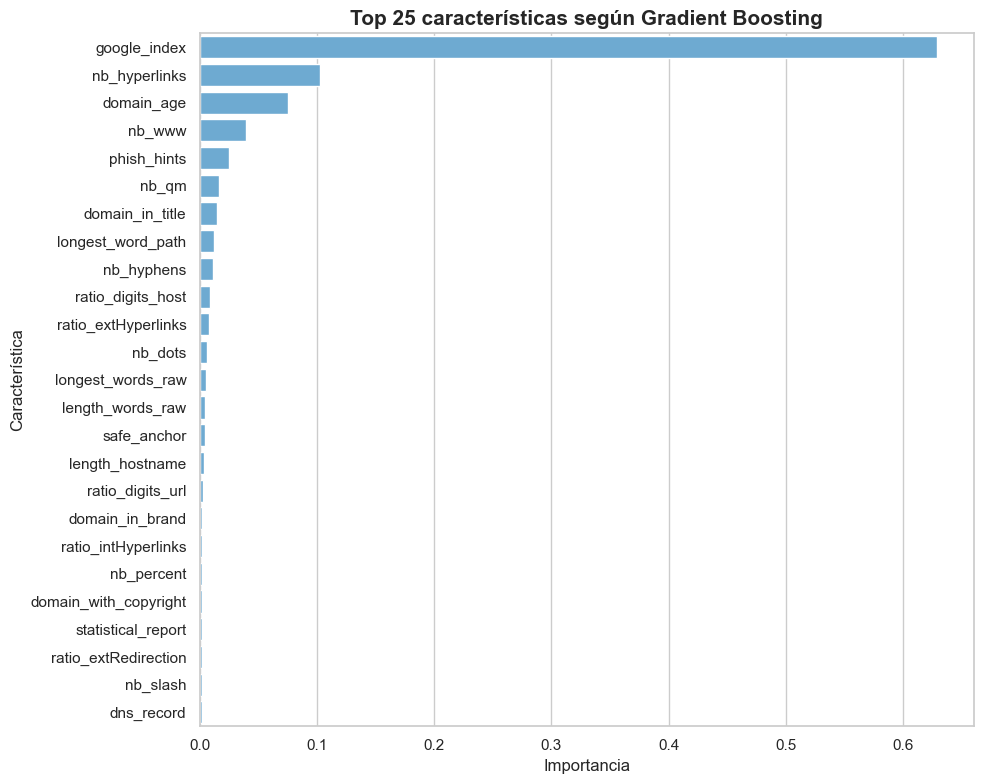

In [8]:
# ============================================================
# Celda 8: Importancia de características con Gradient Boosting
# ============================================================
# En esta celda se entrena un modelo Gradient Boosting para obtener
# otra medida de importancia de variables. Esto permite comparar
# la relevancia de las características desde otro modelo basado en árboles.

gb_selector = GradientBoostingClassifier(
    random_state=42
)

gb_selector.fit(X_train, y_train)

gb_importance = pd.DataFrame({
    "feature": X.columns,
    "gb_importance": gb_selector.feature_importances_
}).sort_values("gb_importance", ascending=False)

display(gb_importance.head(TOP_N))

plt.figure(figsize=(10, 8))
sns.barplot(
    data=gb_importance.head(TOP_N),
    y="feature",
    x="gb_importance",
    color=COLOR_SECUNDARIO
)
plt.title(f"Top {TOP_N} características según Gradient Boosting", fontsize=15, fontweight="bold")
plt.xlabel("Importancia")
plt.ylabel("Característica")
plt.tight_layout()
plt.show()

,feature,mutual_info
78,google_index,0.303615
76,domain_age,0.267663
56,ratio_intHyperlinks,0.245986
55,nb_hyperlinks,0.242667
57,ratio_extHyperlinks,0.239848
68,safe_anchor,0.182688
75,domain_registration_length,0.144686
59,ratio_extRedirection,0.129305
63,links_in_tags,0.116368
45,longest_word_path,0.111853


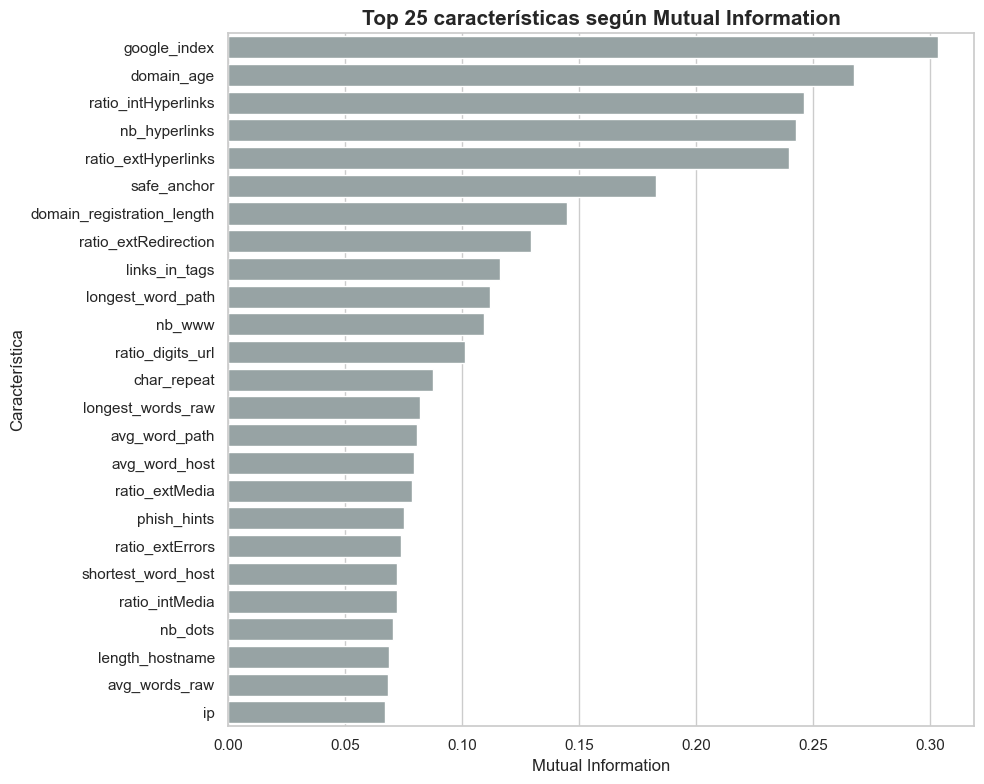

In [9]:
# ============================================================
# Celda 9: Importancia estadística con Mutual Information
# ============================================================
# En esta celda se calcula Mutual Information, una técnica estadística
# que estima cuánta información aporta cada variable respecto al target.
# Es útil porque no depende directamente de un modelo predictivo.

mi_scores = mutual_info_classif(
    X_train,
    y_train,
    random_state=42
)

mi_importance = pd.DataFrame({
    "feature": X.columns,
    "mutual_info": mi_scores
}).sort_values("mutual_info", ascending=False)

display(mi_importance.head(TOP_N))

plt.figure(figsize=(10, 8))
sns.barplot(
    data=mi_importance.head(TOP_N),
    y="feature",
    x="mutual_info",
    color=COLOR_TERCIARIO
)
plt.title(f"Top {TOP_N} características según Mutual Information", fontsize=15, fontweight="bold")
plt.xlabel("Mutual Information")
plt.ylabel("Característica")
plt.tight_layout()
plt.show()

,feature,permutation_importance
78,google_index,0.062043
76,domain_age,0.013466
49,phish_hints,0.011942
55,nb_hyperlinks,0.006119
19,nb_www,0.004822
4,nb_hyphens,0.003079
12,nb_slash,0.002758
24,ratio_digits_url,0.002644
72,domain_in_title,0.002606
68,safe_anchor,0.002041


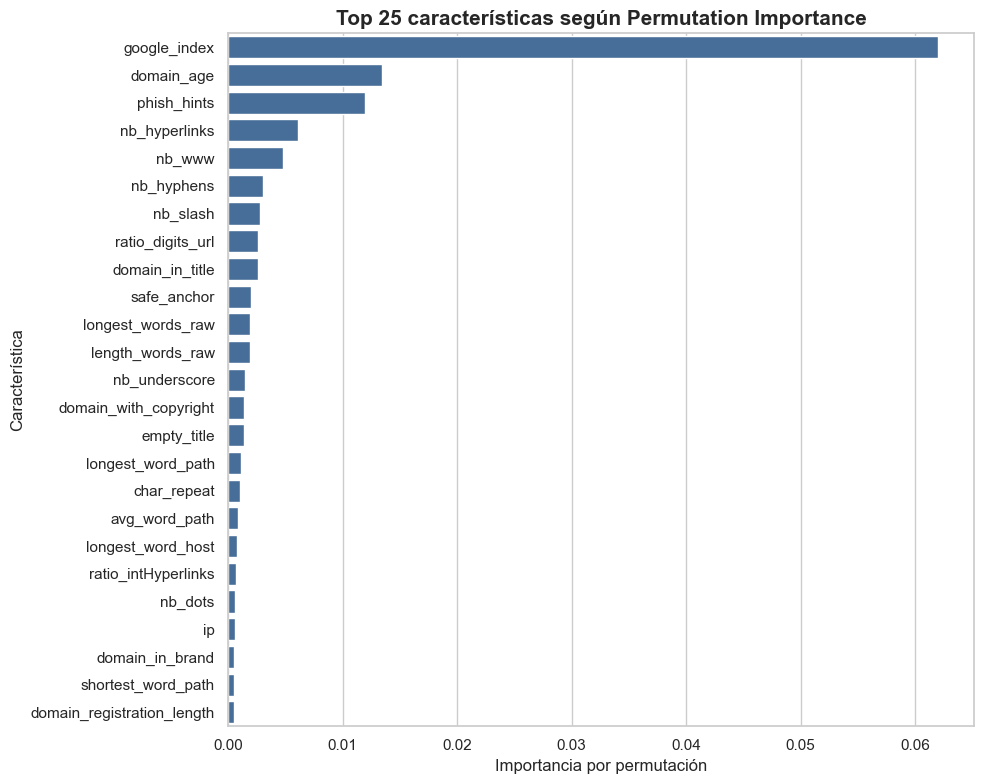

In [10]:
# ============================================================
# Celda 10: Importancia por permutación
# ============================================================
# En esta celda se calcula la importancia por permutación usando
# el modelo Random Forest entrenado. Esta técnica mide cuánto cae
# el rendimiento del modelo cuando se altera aleatoriamente una variable.

perm_result = permutation_importance(
    rf_selector,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    n_jobs=-1,
    scoring="f1"
)

perm_importance = pd.DataFrame({
    "feature": X.columns,
    "permutation_importance": perm_result.importances_mean
}).sort_values("permutation_importance", ascending=False)

display(perm_importance.head(TOP_N))

plt.figure(figsize=(10, 8))
sns.barplot(
    data=perm_importance.head(TOP_N),
    y="feature",
    x="permutation_importance",
    color=COLOR_PRIMARIO
)
plt.title(f"Top {TOP_N} características según Permutation Importance", fontsize=15, fontweight="bold")
plt.xlabel("Importancia por permutación")
plt.ylabel("Característica")
plt.tight_layout()
plt.show()

,feature,rf_importance,gb_importance,mutual_info,permutation_importance,rank_rf,rank_gb,rank_mi,rank_perm,rank_promedio
15,google_index,0.197725,0.628975,0.303615,0.062043,1.0,1.0,1.0,1.0,1.00
8,domain_age,0.052582,0.075069,0.267663,0.013466,4.0,3.0,2.0,2.0,2.75
39,nb_hyperlinks,0.088053,0.102220,0.242667,0.006119,2.0,2.0,4.0,4.0,3.00
51,nb_www,0.052957,0.039148,0.109399,0.004822,3.0,4.0,11.0,5.0,5.75
54,phish_hints,0.036258,0.024676,0.075212,0.011942,6.0,5.0,18.0,3.0,8.00
69,safe_anchor,0.029790,0.004229,0.182688,0.002041,9.0,15.0,6.0,10.0,10.00
26,longest_word_path,0.032205,0.012573,0.111853,0.001111,8.0,8.0,10.0,16.0,10.50
61,ratio_digits_url,0.029337,0.003191,0.101434,0.002644,10.0,17.0,12.0,8.0,11.75
66,ratio_intHyperlinks,0.032881,0.002182,0.245986,0.000739,7.0,19.0,3.0,20.0,12.25
27,longest_words_raw,0.019583,0.005642,0.082182,0.001926,14.0,13.0,14.0,11.0,13.00


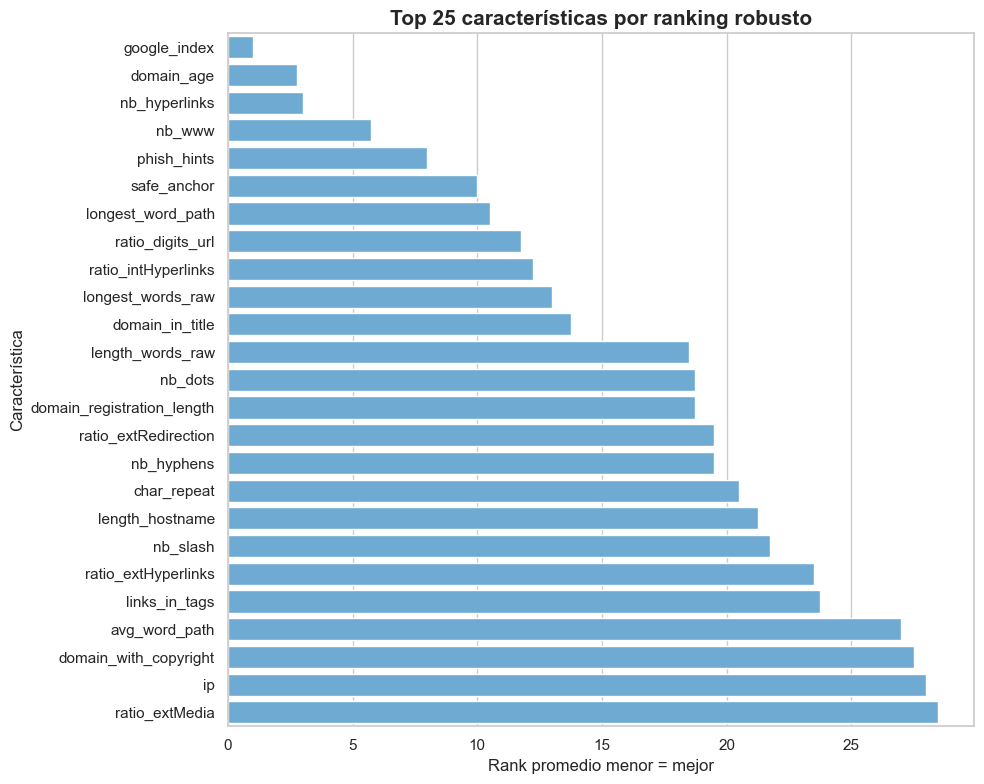

In [11]:
# ============================================================
# Celda 11: Ranking robusto combinado de características
# ============================================================
# En esta celda se combinan los rankings obtenidos por Random Forest,
# Gradient Boosting, Mutual Information y Permutation Importance.
# El objetivo es reducir el sesgo de usar un único método de selección.

ranking_features = (
    rf_importance
    .merge(gb_importance, on="feature", how="outer")
    .merge(mi_importance, on="feature", how="outer")
    .merge(perm_importance, on="feature", how="outer")
)

ranking_features = ranking_features.fillna(0)

ranking_features["rank_rf"] = ranking_features["rf_importance"].rank(
    ascending=False
)

ranking_features["rank_gb"] = ranking_features["gb_importance"].rank(
    ascending=False
)

ranking_features["rank_mi"] = ranking_features["mutual_info"].rank(
    ascending=False
)

ranking_features["rank_perm"] = ranking_features["permutation_importance"].rank(
    ascending=False
)

ranking_features["rank_promedio"] = ranking_features[
    ["rank_rf", "rank_gb", "rank_mi", "rank_perm"]
].mean(axis=1)

ranking_features = ranking_features.sort_values("rank_promedio", ascending=True)

display(ranking_features.head(TOP_N))

plt.figure(figsize=(10, 8))
sns.barplot(
    data=ranking_features.head(TOP_N),
    y="feature",
    x="rank_promedio",
    color=COLOR_SECUNDARIO
)
plt.title(f"Top {TOP_N} características por ranking robusto", fontsize=15, fontweight="bold")
plt.xlabel("Rank promedio menor = mejor")
plt.ylabel("Característica")
plt.tight_layout()
plt.show()

In [12]:
# ============================================================
# Celda 12: Selección final de características Top N global
# ============================================================
# En esta celda se seleccionan las TOP_N características mejor posicionadas
# según el ranking robusto combinado.

TOP_FEATURES = ranking_features.head(TOP_N)["feature"].tolist()

print(f"Top {TOP_N} características seleccionadas:")
print(TOP_FEATURES)

print("\nCantidad de características seleccionadas:", len(TOP_FEATURES))

Top 25 características seleccionadas:
['google_index', 'domain_age', 'nb_hyperlinks', 'nb_www', 'phish_hints', 'safe_anchor', 'longest_word_path', 'ratio_digits_url', 'ratio_intHyperlinks', 'longest_words_raw', 'domain_in_title', 'length_words_raw', 'nb_dots', 'domain_registration_length', 'ratio_extRedirection', 'nb_hyphens', 'char_repeat', 'length_hostname', 'nb_slash', 'ratio_extHyperlinks', 'links_in_tags', 'avg_word_path', 'domain_with_copyright', 'ip', 'ratio_extMedia']

Cantidad de características seleccionadas: 25


In [13]:
# ============================================================
# Celda 13: Creación del dataset con características seleccionadas
# ============================================================
# En esta celda se genera un nuevo dataset compuesto únicamente por:
# URL, características seleccionadas y variable objetivo.
# Este dataset será usado en los siguientes notebooks para ingeniería
# de características y modelado.

df_selected = df[["url"] + TOP_FEATURES + [TARGET_COL]].copy()

print("Shape dataset seleccionado:", df_selected.shape)

display(df_selected.head())

Shape dataset seleccionado: (11429, 27)


,url,google_index,domain_age,nb_hyperlinks,nb_www,phish_hints,safe_anchor,longest_word_path,ratio_digits_url,ratio_intHyperlinks,longest_words_raw,domain_in_title,length_words_raw,nb_dots,domain_registration_length,ratio_extRedirection,nb_hyphens,char_repeat,length_hostname,nb_slash,ratio_extHyperlinks,links_in_tags,avg_word_path,domain_with_copyright,ip,ratio_extMedia,status
0,http://www.crestonwood.com/router.php,1,-1,17,1,0,0.0,6,0.000000,0.529412,11,0,4,3,45,0.875000,0,4,19,3,0.470588,80.000000,4.500000,1,0,0.000000,0
1,http://shadetreetechnology.com/V4/validation/a...,1,5767,30,0,0,100.0,32,0.220779,0.966667,32,1,4,1,77,0.000000,0,4,23,5,0.033333,100.000000,14.666667,0,1,20.000000,1
2,https://support-appleld.com.secureupdate.duila...,1,4004,4,0,0,100.0,17,0.150794,1.000000,17,1,12,4,14,0.000000,1,2,50,5,0.000000,100.000000,8.142857,0,1,0.000000,1
3,http://rgipt.ac.in,0,-1,149,0,0,62.5,0,0.000000,0.973154,5,1,1,2,62,0.250000,0,0,11,2,0.026846,100.000000,0.000000,0,0,3.571429,0
4,http://www.iracing.com/tracks/gateway-motorspo...,0,8175,102,1,0,0.0,11,0.000000,0.470588,11,0,6,2,224,0.537037,2,3,15,5,0.529412,76.470588,7.000000,1,0,100.000000,0


In [14]:
# ============================================================
# Celda 14: Guardado del dataset con características seleccionadas
# ============================================================
# En esta celda se guarda el dataset reducido con las características
# seleccionadas. El nombre del archivo incluye el número de variables
# seleccionadas para facilitar la trazabilidad de los experimentos.

OUTPUT_PATH = f"dataset-phishing-selected-top{TOP_N}.csv"

df_selected.to_csv(OUTPUT_PATH, index=False)

print("Dataset con características seleccionadas guardado correctamente.")
print("Archivo:", OUTPUT_PATH)
print("Shape guardado:", df_selected.shape)

Dataset con características seleccionadas guardado correctamente.
Archivo: dataset-phishing-selected-top25.csv
Shape guardado: (11429, 27)


In [15]:
# ============================================================
# Celda 15: Separación de variables por grupo
# ============================================================
# En esta celda se agrupan las características según su origen:
# URL, HTML y servicios externos.

url_features = [
    "length_url","length_hostname","ip","nb_dots","nb_hyphens",
    "nb_at","nb_qm","nb_and","nb_eq","nb_underscore","nb_tilde",
    "nb_percent","nb_slash","nb_star","nb_colon","nb_comma",
    "nb_semicolumn","nb_dollar","nb_space","nb_www","nb_com",
    "nb_dslash","http_in_path","https_token","ratio_digits_url",
    "ratio_digits_host","punycode","port","tld_in_path",
    "tld_in_subdomain","abnormal_subdomain","nb_subdomains",
    "prefix_suffix","random_domain","shortening_service",
    "path_extension","nb_redirection","nb_external_redirection",
    "length_words_raw","char_repeat","shortest_words_raw",
    "shortest_word_host","shortest_word_path","longest_words_raw",
    "longest_word_host","longest_word_path","avg_words_raw",
    "avg_word_host","avg_word_path","phish_hints",
    "domain_in_brand","brand_in_subdomain","brand_in_path",
    "suspecious_tld","statistical_report"
]

html_features = [
    "nb_hyperlinks","ratio_intHyperlinks","ratio_extHyperlinks",
    "nb_extCSS","ratio_extRedirection","ratio_extErrors",
    "login_form","external_favicon","links_in_tags",
    "ratio_intMedia","ratio_extMedia","iframe",
    "popup_window","safe_anchor","onmouseover",
    "right_clic","empty_title","domain_in_title",
    "domain_with_copyright"
]

service_features = [
    "whois_registered_domain",
    "domain_registration_length",
    "domain_age",
    "dns_record",
    "google_index"
]

url_features = [f for f in url_features if f in ranking_features["feature"].values]
html_features = [f for f in html_features if f in ranking_features["feature"].values]
service_features = [f for f in service_features if f in ranking_features["feature"].values]

print("URL:", len(url_features))
print("HTML:", len(html_features))
print("Servicios:", len(service_features))

URL: 55
HTML: 19
Servicios: 5


Top URL:
['nb_www', 'phish_hints', 'longest_word_path', 'ratio_digits_url', 'longest_words_raw', 'length_words_raw', 'nb_dots', 'nb_hyphens', 'char_repeat', 'length_hostname']

Top HTML:
['nb_hyperlinks', 'safe_anchor', 'ratio_intHyperlinks', 'domain_in_title', 'ratio_extRedirection', 'ratio_extHyperlinks', 'links_in_tags', 'domain_with_copyright', 'ratio_extMedia', 'ratio_extErrors']

Top Servicios:
['google_index', 'domain_age', 'domain_registration_length', 'dns_record', 'whois_registered_domain']

Total features balanceadas:
25


,feature,grupo,rank_promedio
0,nb_www,URL,5.750
1,phish_hints,URL,8.000
2,longest_word_path,URL,10.500
3,ratio_digits_url,URL,11.750
4,longest_words_raw,URL,13.000
5,length_words_raw,URL,18.500
6,nb_dots,URL,18.750
7,nb_hyphens,URL,19.500
8,char_repeat,URL,20.500
9,length_hostname,URL,21.250


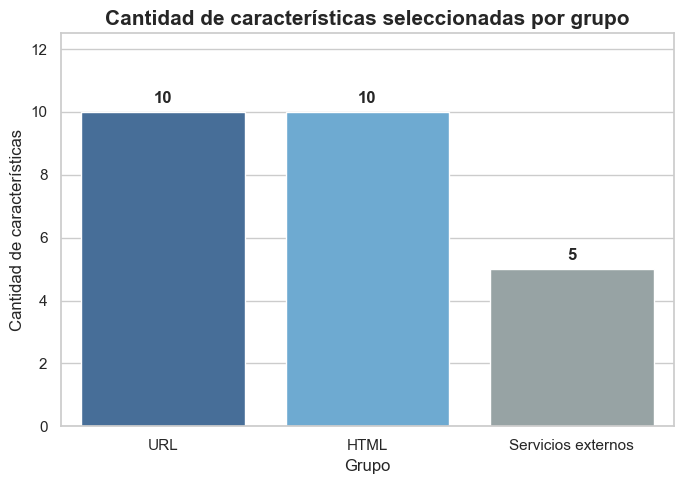

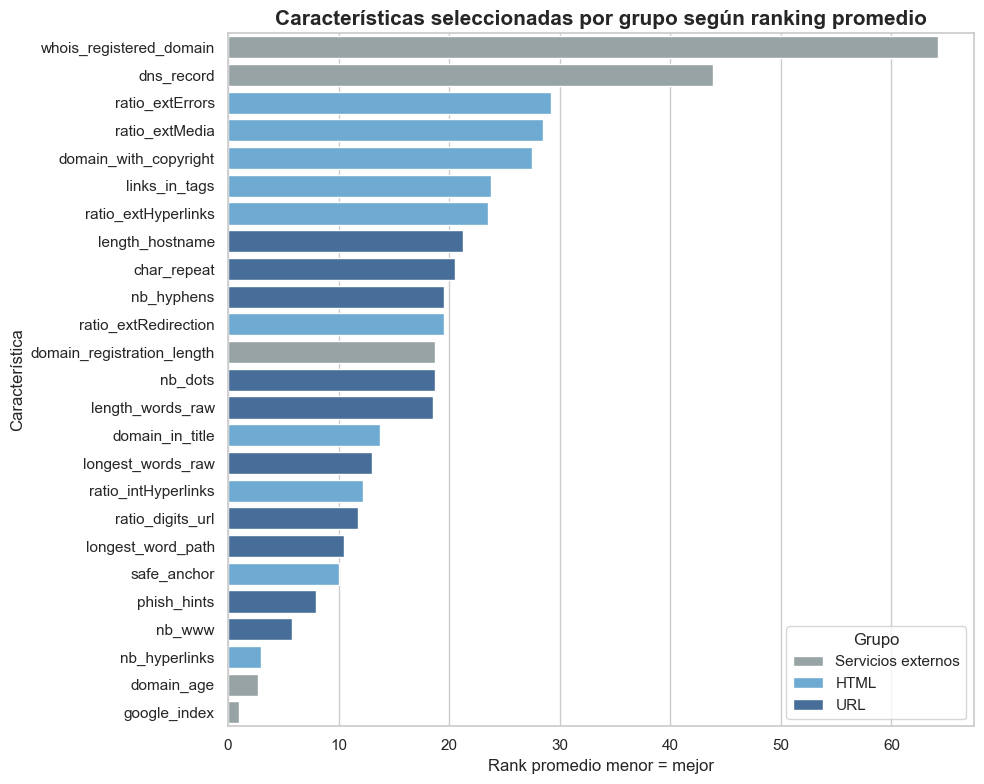

In [16]:
# ============================================================
# Celda 16: Selección Top por grupo de características
# ============================================================
# En esta celda se seleccionan las variables más importantes
# dentro de cada grupo: URL, HTML y servicios externos.
# Además, se visualiza la composición final del conjunto balanceado.

TOP_URL = 10
TOP_HTML = 10
TOP_SERVICE = 5

top_url_features = (
    ranking_features[
        ranking_features["feature"].isin(url_features)
    ]
    .head(TOP_URL)["feature"]
    .tolist()
)

top_html_features = (
    ranking_features[
        ranking_features["feature"].isin(html_features)
    ]
    .head(TOP_HTML)["feature"]
    .tolist()
)

top_service_features = (
    ranking_features[
        ranking_features["feature"].isin(service_features)
    ]
    .head(TOP_SERVICE)["feature"]
    .tolist()
)

TOP_FEATURES_BALANCEADO = (
    top_url_features +
    top_html_features +
    top_service_features
)

print("Top URL:")
print(top_url_features)

print("\nTop HTML:")
print(top_html_features)

print("\nTop Servicios:")
print(top_service_features)

print("\nTotal features balanceadas:")
print(len(TOP_FEATURES_BALANCEADO))

# =========================
# Tabla resumen
# =========================

features_balanceadas_df = pd.DataFrame({
    "feature": TOP_FEATURES_BALANCEADO,
    "grupo": (
        ["URL"] * len(top_url_features) +
        ["HTML"] * len(top_html_features) +
        ["Servicios externos"] * len(top_service_features)
    )
})

features_balanceadas_df = features_balanceadas_df.merge(
    ranking_features[["feature", "rank_promedio"]],
    on="feature",
    how="left"
)

display(features_balanceadas_df)

# =========================
# Gráfico de cantidad por grupo
# =========================

conteo_grupos = features_balanceadas_df["grupo"].value_counts().reset_index()
conteo_grupos.columns = ["grupo", "cantidad"]

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=conteo_grupos,
    x="grupo",
    y="cantidad",
    hue="grupo",
    palette=[COLOR_PRIMARIO, COLOR_SECUNDARIO, COLOR_TERCIARIO],
    legend=False
)

plt.title(
    "Cantidad de características seleccionadas por grupo",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Grupo")
plt.ylabel("Cantidad de características")

for i, row in conteo_grupos.iterrows():
    ax.text(
        i,
        row["cantidad"] + 0.2,
        int(row["cantidad"]),
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold"
    )

plt.ylim(0, conteo_grupos["cantidad"].max() * 1.25)
plt.tight_layout()
plt.show()

# =========================
# Gráfico de ranking promedio por feature
# =========================

features_plot = features_balanceadas_df.sort_values(
    "rank_promedio",
    ascending=False
)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=features_plot,
    y="feature",
    x="rank_promedio",
    hue="grupo",
    palette={
        "URL": COLOR_PRIMARIO,
        "HTML": COLOR_SECUNDARIO,
        "Servicios externos": COLOR_TERCIARIO
    }
)

plt.title(
    "Características seleccionadas por grupo según ranking promedio",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Rank promedio menor = mejor")
plt.ylabel("Característica")
plt.legend(title="Grupo")

plt.tight_layout()
plt.show()

In [17]:
# ============================================================
# Celda 17: Creación del dataset balanceado por grupos
# ============================================================
# En esta celda se crea un dataset utilizando variables balanceadas
# entre URL, HTML y servicios externos.

df_selected_balanceado = df[
    ["url"] + TOP_FEATURES_BALANCEADO + [TARGET_COL]
].copy()

print("Shape dataset balanceado:")
print(df_selected_balanceado.shape)

display(df_selected_balanceado.head())

Shape dataset balanceado:
(11429, 27)


,url,nb_www,phish_hints,longest_word_path,ratio_digits_url,longest_words_raw,length_words_raw,nb_dots,nb_hyphens,char_repeat,length_hostname,nb_hyperlinks,safe_anchor,ratio_intHyperlinks,domain_in_title,ratio_extRedirection,ratio_extHyperlinks,links_in_tags,domain_with_copyright,ratio_extMedia,ratio_extErrors,google_index,domain_age,domain_registration_length,dns_record,whois_registered_domain,status
0,http://www.crestonwood.com/router.php,1,0,6,0.000000,11,4,3,0,4,19,17,0.0,0.529412,0,0.875000,0.470588,80.000000,1,0.000000,0.500000,1,-1,45,1,0,0
1,http://shadetreetechnology.com/V4/validation/a...,0,0,32,0.220779,32,4,1,0,4,23,30,100.0,0.966667,1,0.000000,0.033333,100.000000,0,20.000000,0.000000,1,5767,77,0,0,1
2,https://support-appleld.com.secureupdate.duila...,0,0,17,0.150794,17,12,4,1,2,50,4,100.0,1.000000,1,0.000000,0.000000,100.000000,0,0.000000,0.000000,1,4004,14,0,0,1
3,http://rgipt.ac.in,0,0,0,0.000000,5,1,2,0,0,11,149,62.5,0.973154,1,0.250000,0.026846,100.000000,0,3.571429,0.250000,0,-1,62,0,0,0
4,http://www.iracing.com/tracks/gateway-motorspo...,1,0,11,0.000000,11,6,2,2,3,15,102,0.0,0.470588,0,0.537037,0.529412,76.470588,1,100.000000,0.018519,0,8175,224,0,0,0


In [18]:
# ============================================================
# Celda 18: Guardado del dataset balanceado
# ============================================================
# En esta celda se guarda el dataset construido con selección
# balanceada de características por grupo.

OUTPUT_BALANCEADO = (
    f"dataset-phishing-balanced-"
    f"url{TOP_URL}-html{TOP_HTML}-service{TOP_SERVICE}.csv"
)

df_selected_balanceado.to_csv(
    OUTPUT_BALANCEADO,
    index=False
)

print("Dataset balanceado guardado correctamente.")
print("Archivo:", OUTPUT_BALANCEADO)
print("Shape guardado:", df_selected_balanceado.shape)

Dataset balanceado guardado correctamente.
Archivo: dataset-phishing-balanced-url10-html10-service5.csv
Shape guardado: (11429, 27)
